# 03 · Baseline Generation — 5 Prompt → Image Test Runs

**Milestone 1** · Text-to-Image Generation (CLIP + Stable Diffusion v1.5)

This closes the Milestone 1 pipeline, **caption → CLIP embedding → image**, using pre-trained
**Stable Diffusion v1.5** with default settings and no tuning (tuning is Milestone 2).

1. **Check the hand-off.** The `[77, 768]` CLIP embeddings saved in notebook 02 should equal what SD's own
   `encode_prompt` computes, so SD can consume them directly.
2. **Generate 5 images** from **real COCO test-split captions**, passing the saved embeddings in through `prompt_embeds`.
   Each one is shown next to the real photo the caption describes.
3. **Score them** with CLIP similarity (generated image vs prompt), using the real photo's score as a reference.

**Prerequisites:** notebooks 01 and 02. The first run downloads the SD v1.5 weights (~5 GB) from Hugging Face.

## 0. Setup

In [1]:
import json
import sys
import textwrap
import time
from datetime import datetime, timezone
from pathlib import Path

import diffusers
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import transformers
from diffusers import StableDiffusionPipeline
from PIL import Image
from transformers import CLIPImageProcessor, CLIPModel, CLIPTokenizer

transformers.logging.set_verbosity_error()
diffusers.logging.set_verbosity_error()

ROOT = Path.cwd().resolve()
while not (ROOT / "pyproject.toml").exists():
    if ROOT.parent == ROOT:
        raise FileNotFoundError("Could not find pyproject.toml - open this notebook inside the project.")
    ROOT = ROOT.parent
PROC_DIR = ROOT / "data" / "processed"
EMB_DIR = PROC_DIR / "embeddings"
OUT_DIR = ROOT / "outputs" / "milestone1_samples"
FIG_DIR = ROOT / "outputs" / "figures"
OUT_DIR.mkdir(parents=True, exist_ok=True); FIG_DIR.mkdir(parents=True, exist_ok=True)

# ---- Configuration: Stable Diffusion defaults, no tuning ----------------------------
SEED = 42
SD_ID = "stable-diffusion-v1-5/stable-diffusion-v1-5"   # official mirror (runwayml/... was removed in 2024)
CLIP_ID = "openai/clip-vit-large-patch14"
N_SAMPLES = 5
NUM_STEPS = 30
GUIDANCE = 7.5
SIZE = 512

if torch.cuda.is_available():
    DEVICE, DTYPE = "cuda", torch.float16
elif torch.backends.mps.is_available():
    DEVICE, DTYPE = "mps", torch.float32      # float16 on MPS can produce NaN/black images with SD v1.5
else:
    DEVICE, DTYPE = "cpu", torch.float32
plt.rcParams.update({"figure.dpi": 110})
%config InlineBackend.figure_formats = ["jpeg"]
%config InlineBackend.print_figure_kwargs = {"bbox_inches": "tight", "pil_kwargs": {"quality": 85}}

pairs = pd.read_parquet(PROC_DIR / "pairs.parquet").sort_values("image_id").reset_index(drop=True)
tok_store = torch.load(EMB_DIR / "clip_text_tokens.pt")
assert tok_store["caption_id"].tolist() == pairs.caption_id.tolist()
print(f"Device: {DEVICE} ({DTYPE}) | torch {torch.__version__} | diffusers {diffusers.__version__}")
print(f"Saved conditioning tensors: {tuple(tok_store['emb'].shape)}")

W1104 23:52:33.344000 99472 torch/distributed/elastic/multiprocessing/redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


Device: mps (torch.float32) | torch 2.11.0 | diffusers 0.42.1
Saved conditioning tensors: (4000, 77, 768)


## 1. Choose the 5 prompts
The prompts are primary captions from the **test split**, one per supercategory, so they cover different
kinds of scenes (people, animals, vehicles, food, furniture). The selection is seeded.

In [2]:
test = pairs[pairs.split == "test"]
wanted = ["person", "animal", "vehicle", "food", "furniture"]
chosen = pd.concat([test[test.supercategory == c].sample(1, random_state=SEED)
                    for c in wanted[:N_SAMPLES]], ignore_index=True)
chosen["row"] = [pairs.index[pairs.caption_id == c][0] for c in chosen.caption_id]   # row in the embedding store
chosen[["supercategory", "image_id", "caption"]]

,supercategory,image_id,caption
0,person,553731,a clown is standing in a cable car and talking...
1,animal,178618,an elephant is standing in a dirt field
2,vehicle,6723,a street with a row of older red brick buildin...
3,food,141821,gourmet food on a picnic table with drinks
4,furniture,455937,the man is in his living room playing a video ...


## 2. Load Stable Diffusion v1.5

In [3]:
t0 = time.perf_counter()
pipe = StableDiffusionPipeline.from_pretrained(SD_ID, dtype=DTYPE).to(DEVICE)
if DEVICE == "mps":
    pipe.enable_attention_slicing()           # recommended on Apple Silicon with < 64 GB memory
pipe.set_progress_bar_config(disable=True)
print(f"Loaded in {time.perf_counter() - t0:.0f}s")
for name in ("text_encoder", "unet", "vae", "safety_checker"):
    m = getattr(pipe, name)
    print(f"  {name:15s} {type(m).__name__:30s} {sum(p.numel() for p in m.parameters()) / 1e6:7.0f}M params")
print(f"  scheduler       {type(pipe.scheduler).__name__}")

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loaded in 3s
  text_encoder    CLIPTextModel                      123M params
  unet            UNet2DConditionModel               860M params
  vae             AutoencoderKL                       84M params
  safety_checker  StableDiffusionSafetyChecker       304M params
  scheduler       PNDMScheduler


## 3. Hand-off check: notebook 02 embeddings = SD's own text encoding
If the saved tensors match `pipe.encode_prompt` for the same captions, notebook 02 has produced exactly what SD
conditions on. The tolerance allows for the float16 storage of the saved tensors.

In [4]:
with torch.no_grad():
    sd_cond, sd_uncond = pipe.encode_prompt(chosen.caption.tolist(), device=DEVICE, num_images_per_prompt=1,
                                            do_classifier_free_guidance=True, negative_prompt=None)
saved_cond = tok_store["emb"][chosen.row.values].float()
saved_uncond = tok_store["uncond"].float()

diff_cond = (sd_cond.float().cpu() - saved_cond).abs()
diff_uncond = (sd_uncond[:1].float().cpu() - saved_uncond).abs()
cos = F.cosine_similarity(sd_cond.float().cpu().flatten(1), saved_cond.flatten(1)).min()
print(f"SD encode_prompt shape     : {tuple(sd_cond.shape)}")
print(f"captions  - max |diff| {diff_cond.max():.4f}, mean {diff_cond.mean():.6f}, min cosine {cos:.6f}")
print(f"empty \"\"  - max |diff| {diff_uncond.max():.4f}")
assert cos > 0.9999 and diff_cond.mean() < 1e-3, "saved embeddings do not match SD's text encoder"
print("Match: SD can be driven directly by the embeddings saved in notebook 02.")

SD encode_prompt shape     : (5, 77, 768)
captions  - max |diff| 0.0039, mean 0.000134, min cosine 0.999996
empty ""  - max |diff| 0.0025
Match: SD can be driven directly by the embeddings saved in notebook 02.


## 4. Generate the 5 sample images
Each image uses its own seeded CPU generator (`SEED + i`), so every result can be reproduced exactly on any device.
The text goes in **only as the saved embeddings** (`prompt_embeds` / `negative_prompt_embeds`). Settings are SD's defaults:
PNDM scheduler, 30 steps, guidance scale 7.5, 512×512.

In [5]:
results = []
for i, row in enumerate(chosen.itertuples()):
    gen = torch.Generator("cpu").manual_seed(SEED + i)
    cond = tok_store["emb"][row.row].unsqueeze(0).to(DEVICE, DTYPE)
    uncond = tok_store["uncond"].to(DEVICE, DTYPE)
    t0 = time.perf_counter()
    with torch.no_grad():
        out = pipe(prompt_embeds=cond, negative_prompt_embeds=uncond, num_inference_steps=NUM_STEPS,
                   guidance_scale=GUIDANCE, height=SIZE, width=SIZE, generator=gen)
    secs = time.perf_counter() - t0
    img = out.images[0]
    path = OUT_DIR / f"sample_{i + 1}_{row.supercategory}.png"
    img.save(path)
    flagged = bool(out.nsfw_content_detected and out.nsfw_content_detected[0])
    results.append({"sample": i + 1, "supercategory": row.supercategory, "image_id": int(row.image_id),
                    "prompt": row.caption, "seed": SEED + i, "seconds": round(secs, 1),
                    "nsfw_flagged": flagged, "path": path.relative_to(ROOT).as_posix()})
    print(f"[{i + 1}/{N_SAMPLES}] {secs:5.1f}s  {row.caption}" + ("  (flagged by safety checker)" if flagged else ""))
results = pd.DataFrame(results)
print(f"\nMean generation time: {results.seconds.mean():.1f}s per image on {DEVICE}")

[1/5]  23.4s  a clown is standing in a cable car and talking on a cell phone


[2/5]  23.3s  an elephant is standing in a dirt field


[3/5]  23.3s  a street with a row of older red brick building on one side


[4/5]  23.3s  gourmet food on a picnic table with drinks


[5/5]  23.2s  the man is in his living room playing a video game

Mean generation time: 23.3s per image on mps


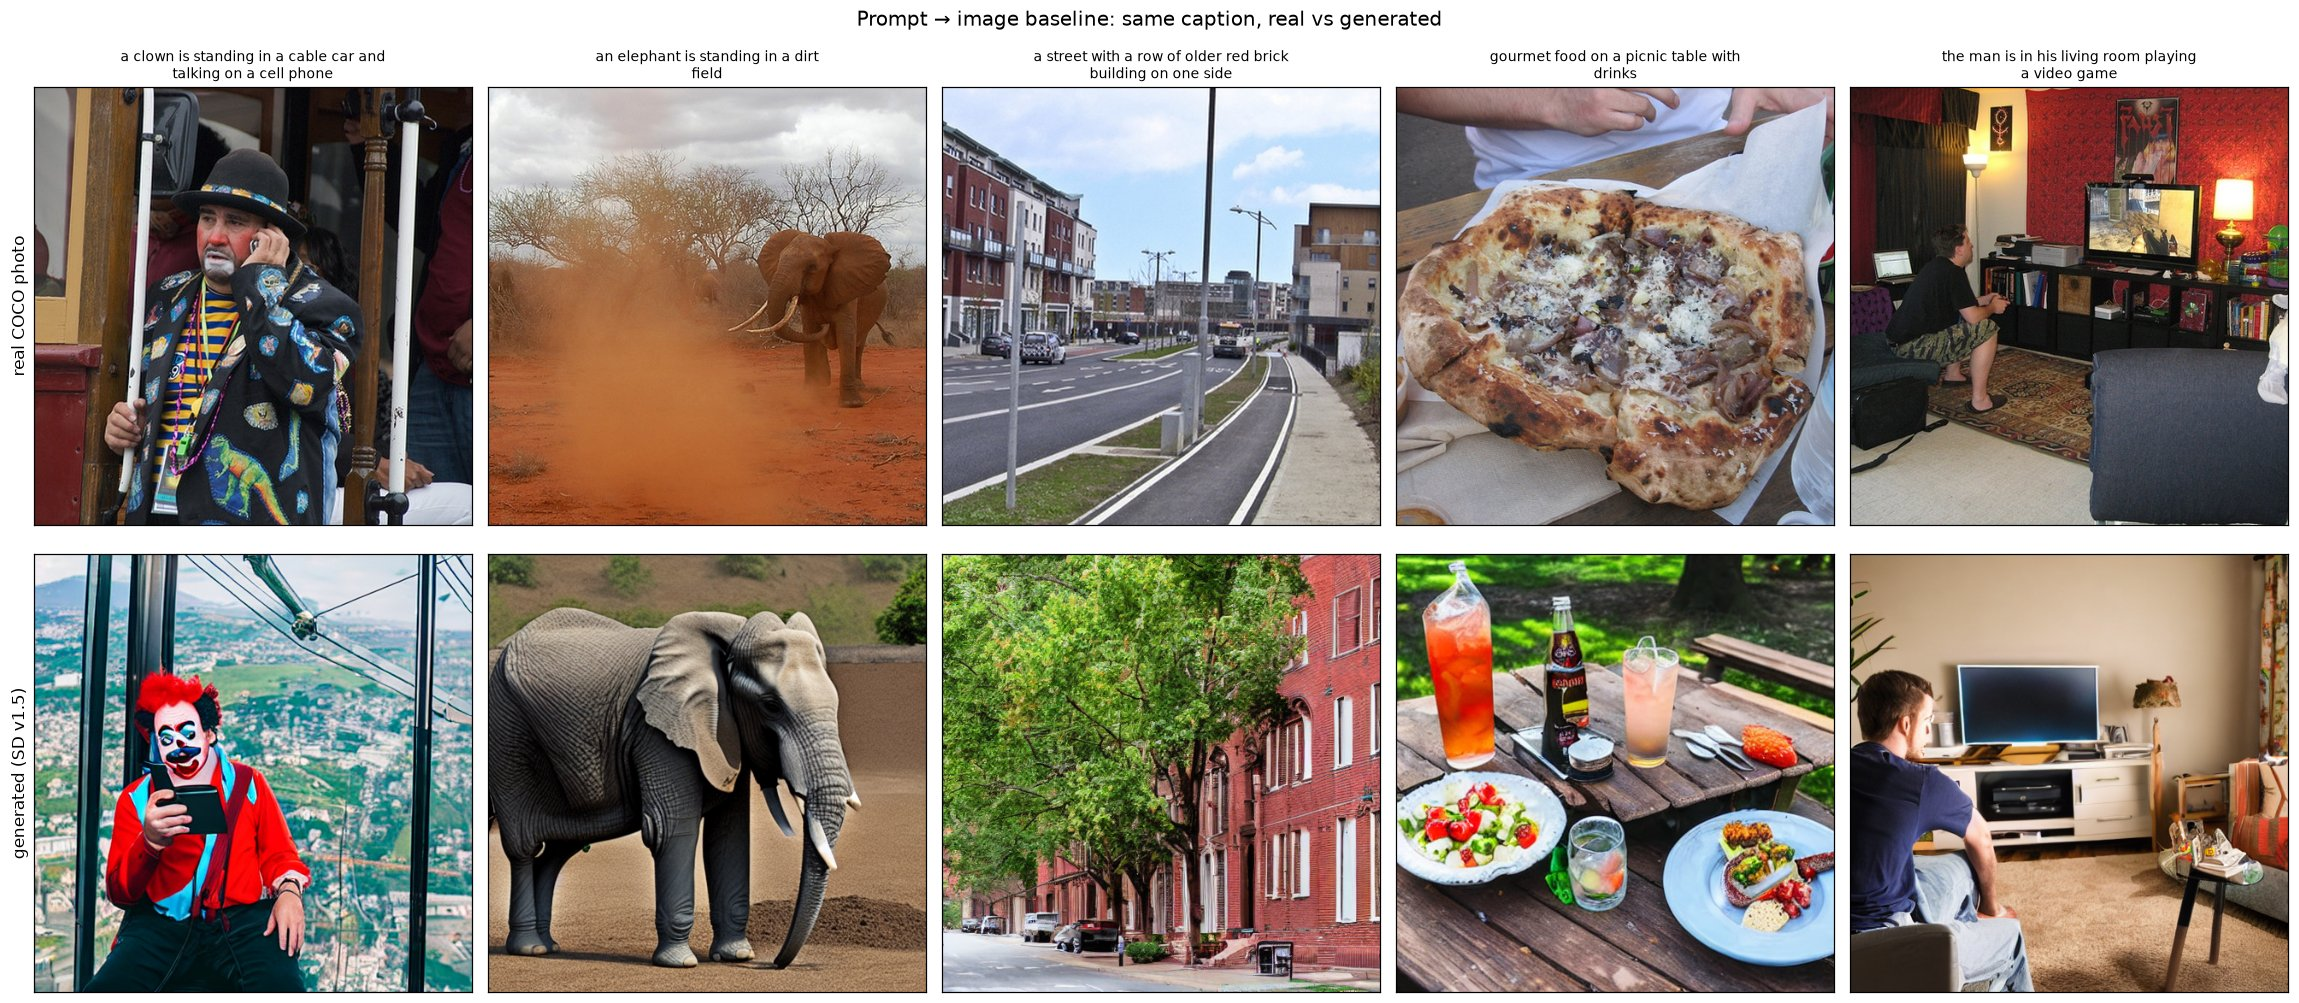

In [6]:
fig, axes = plt.subplots(2, N_SAMPLES, figsize=(4.2 * N_SAMPLES, 9.6))
for j, (row, res) in enumerate(zip(chosen.itertuples(), results.itertuples())):
    axes[0, j].imshow(Image.open(ROOT / row.image_path))
    axes[1, j].imshow(Image.open(ROOT / res.path))
    axes[0, j].set_title(textwrap.fill(row.caption, 38), fontsize=9)
for ax in axes.flat:
    ax.set_xticks([]); ax.set_yticks([])
axes[0, 0].set_ylabel("real COCO photo", fontsize=11)
axes[1, 0].set_ylabel("generated (SD v1.5)", fontsize=11)
fig.suptitle("Prompt → image baseline: same caption, real vs generated", fontsize=13)
fig.tight_layout(); fig.savefig(FIG_DIR / "03_real_vs_generated.png", bbox_inches="tight"); plt.show()

## 5. CLIP similarity: does each image match its prompt?
We use CLIP ViT-L/14 to embed each generated image and compute its cosine similarity with the prompt.
The **real** COCO photo for the same caption, scored the same way, is the reference: a generated image
scoring at or above it matches the text about as well as a real photo does. *(CLIP score = 100 × cosine.
With 5 images this is a sanity check, not an evaluation. Milestone 3 covers proper metrics.)*

In [7]:
pipe.to("cpu"); del pipe                                   # free GPU memory before loading CLIP
if DEVICE == "mps":
    torch.mps.empty_cache()
clip = CLIPModel.from_pretrained(CLIP_ID).eval().to(DEVICE)
clip_tok = CLIPTokenizer.from_pretrained(CLIP_ID)
img_proc = CLIPImageProcessor.from_pretrained(CLIP_ID)

@torch.no_grad()
def clip_image_vecs(paths):
    px = img_proc(images=[Image.open(ROOT / p).convert("RGB") for p in paths], return_tensors="pt").pixel_values
    return F.normalize(clip.visual_projection(clip.vision_model(pixel_values=px.to(DEVICE)).pooler_output), dim=-1)

@torch.no_grad()
def clip_text_vecs(texts):
    ids = clip_tok(list(texts), padding="max_length", max_length=77, truncation=True, return_tensors="pt").input_ids
    return F.normalize(clip.text_projection(clip.text_model(input_ids=ids.to(DEVICE)).pooler_output), dim=-1)

T = clip_text_vecs(chosen.caption)
G = clip_image_vecs(results.path)
R = clip_image_vecs(chosen.image_path)

results["clip_score_generated"] = (100 * (T * G).sum(-1)).cpu().double().numpy().round(2)
results["clip_score_real_photo"] = (100 * (T * R).sum(-1)).cpu().double().numpy().round(2)
S = (T @ G.T).cpu().numpy()
results["prompt_matches_own_image"] = S.argmax(0) == np.arange(len(S))
results[["sample", "supercategory", "prompt", "seconds", "clip_score_generated", "clip_score_real_photo",
         "prompt_matches_own_image"]]

,sample,supercategory,prompt,seconds,clip_score_generated,clip_score_real_photo,prompt_matches_own_image
0,1,person,a clown is standing in a cable car and talking...,23.4,34.40,36.32,True
1,2,animal,an elephant is standing in a dirt field,23.3,28.03,26.25,True
2,3,vehicle,a street with a row of older red brick buildin...,23.3,23.58,15.37,True
3,4,food,gourmet food on a picnic table with drinks,23.3,26.66,22.66,True
4,5,furniture,the man is in his living room playing a video ...,23.2,20.02,25.42,True


In [8]:
print(f"Mean CLIP score - generated: {results.clip_score_generated.mean():.2f} | "
      f"real photos: {results.clip_score_real_photo.mean():.2f}")
print(f"Each generated image is closest to its own prompt (out of the 5): "
      f"{results.prompt_matches_own_image.sum()} / {len(results)}")

run_info = {
    "created_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "model": SD_ID, "device": DEVICE, "dtype": str(DTYPE).replace("torch.", ""),
    "settings": {"scheduler": "PNDMScheduler (default)", "num_inference_steps": NUM_STEPS,
                 "guidance_scale": GUIDANCE, "height": SIZE, "width": SIZE,
                 "conditioning": "prompt_embeds from data/processed/embeddings/clip_text_tokens.pt"},
    "embedding_match": {"max_abs_diff": round(float(diff_cond.max()), 5), "min_cosine": round(float(cos), 6)},
    "samples": results.to_dict(orient="records"),
    "versions": {"python": sys.version.split()[0], "torch": torch.__version__,
                 "diffusers": diffusers.__version__, "transformers": transformers.__version__},
}
(OUT_DIR / "samples.json").write_text(json.dumps(run_info, indent=2, default=str))
print(f"Saved {len(results)} images + samples.json to {OUT_DIR.relative_to(ROOT)}/")

Mean CLIP score - generated: 26.54 | real photos: 25.20
Each generated image is closest to its own prompt (out of the 5): 5 / 5
Saved 5 images + samples.json to outputs/milestone1_samples/


## Summary
**Pipeline:** caption → CLIP ViT-L/14 embedding (saved in notebook 02) → Stable Diffusion v1.5 → 512×512 image.
The saved embeddings match SD's own text encoding (minimum cosine ≈ 0.99999; the tiny difference is float16 storage),
so the hand-off between the two notebooks is exact. SD's default settings (PNDM, 30 steps, guidance 7.5) take
**about 24 s per image** on an Apple M5 GPU at float32.

**What worked**
* All 5 images clearly show the main subject and setting of their prompt: a clown with a phone, an elephant on
  dirt, red-brick buildings along a street, food and drinks on an outdoor table, a man in a living room facing a TV.
* Each generated image is closer (by CLIP) to **its own** prompt than to the other four, and the mean CLIP score
  of the generated images is close to that of the real COCO photos for the same captions (table above).

**Baseline weaknesses to address in Milestone 2**
* **Actions and relations get simplified.** *"Playing a video game"* becomes a man sitting in front of a TV with no
  controller, and *"talking on a cell phone"* becomes looking at a phone. The objects are right; the interaction is weak.
* **Scene interpretation drifts.** *"Cable car"* is rendered as an aerial gondola above a city rather than a street tram.
* **Fine detail breaks down.** The clown's face is distorted, and the text on the bottle label is garbled.
  Both are typical of SD v1.5 at default settings.

**On the CLIP scores:** a generated image can score *higher* than the real photo (3 of 5 here). SD draws what the
caption literally says, while real photos contain things the caption leaves out. The street caption scores only ~15
against its own real photo. CLIP score therefore measures **prompt adherence, not realism**, which is why
Milestone 3 adds FID / Inception Score on a larger sample.

**Outputs:** `outputs/milestone1_samples/sample_*.png` and `samples.json` (prompts, seeds, settings, timings, scores),
plus `outputs/figures/03_real_vs_generated.png`.

**Next (Milestone 2):** tune guidance scale, inference steps and scheduler, try negative prompts, and measure
how they affect prompt adherence and speed.